In [1]:
from fit_file import X_sq
import numpy as np

In [2]:
### opzetten van de fit, dataset 1 en 2
file_name1 = 'meetingen massa 1.txt'
freq1, amp1, phase1, dfreq1, damp1, dphase1 = np.loadtxt(file_name1, unpack = True)
phase1 = phase1 + np.pi

file_name2 = 'meetingen massa 2.txt'
freq2, amp2, phase2, dfreq2, damp2, dphase2 = np.loadtxt(file_name2, unpack = True)

In [3]:
### modellen

def amplitude(params, freq):
    u, b, omega0 = params #u = F0/m, b = eta/m
    amp = u / (np.sqrt((omega0**2 - freq**2)**2 + (freq * b)**2))
    return amp

def faseverschil(params, freq):
    b, omega0 = params #b = eta/m
    phase = -np.arctan2(freq * b, omega0**2 - freq**2)
    return phase


---------START--------------------------------------------------------------------------------------------------


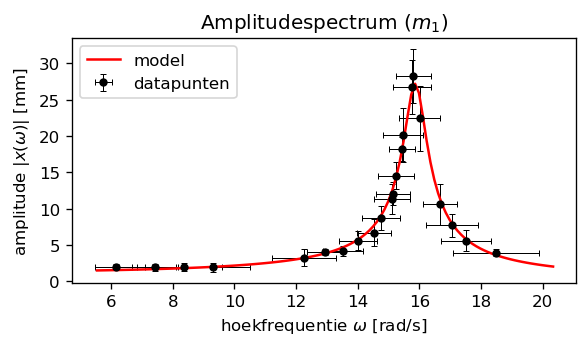

For parameter $\frac{F_0}{m}$ :     Minimum at     325.79771596     ;     68% CI = [    304.23110864,     347.36431804]
For parameter $\frac{\eta}{m}$ :     Minimum at       0.75442980     ;     68% CI = [      0.65007903,       0.88395744]
For parameter $\omega_0$ :     Minimum at      15.87811443     ;     68% CI = [     15.80781720,      15.95425936]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min           4.34405022
Reduced χ² value       :     χ²_red           0.22863422
P-value                :     p-value          0.99980007


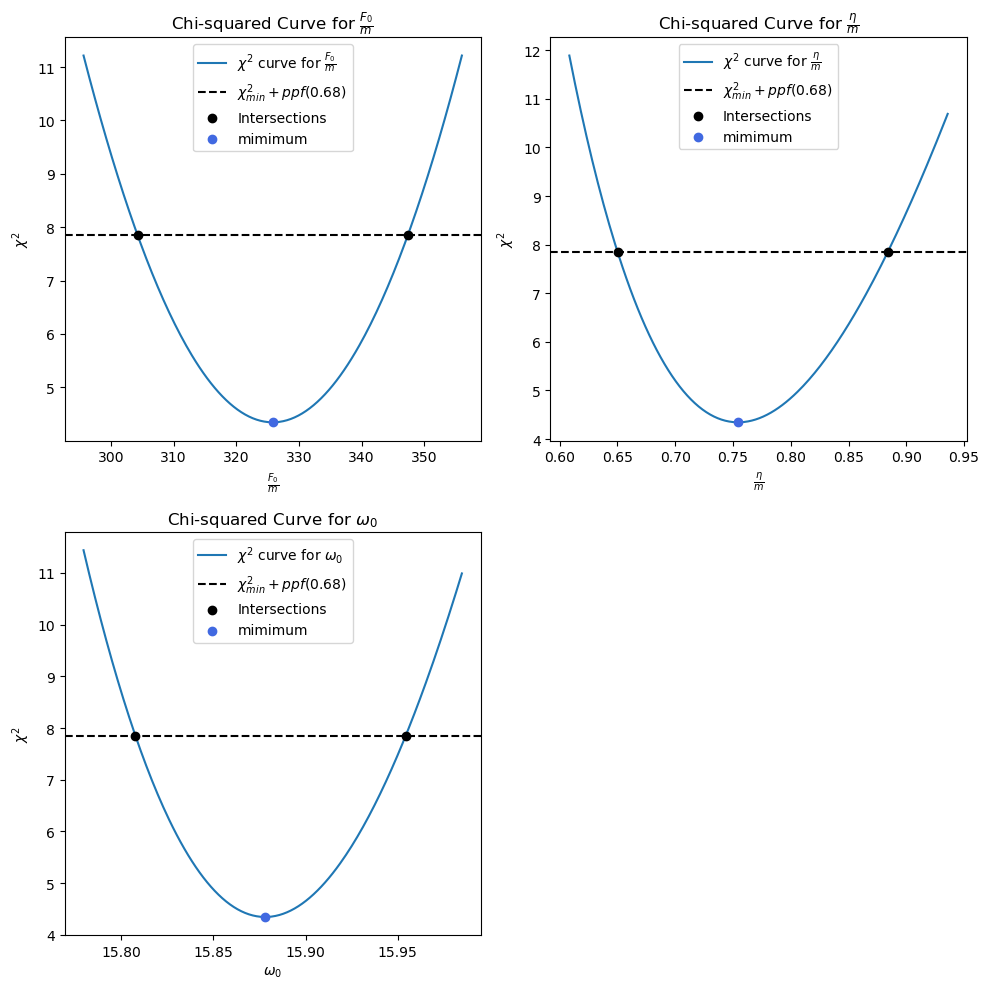

----------END---------------------------------------------------------------------------------------------------

21.566607320000003 0.10435077000000004 0.12952763999999994 0.07029722999999954 -0.07614492999999989


In [5]:
###########################################
#FITTEN DATASET 1
###########################################

###AMPLITUDE

#tampering: geen nullen in de fouten van de amplitude
#3 eerste waarden van freq weg

param_names = [r'$\frac{F_0}{m}$', r'$\frac{\eta}{m}$', r'$\omega_0$']
title = r'Amplitudespectrum ($m_1$)'
x_label = r'hoekfrequentie $\omega$ [rad/s]'
y_label = r'amplitude $|{x(\omega)}|$ [mm]'

X_sq(((freq1[3:], dfreq1[3:]), (amp1[3:], damp1[3:])), param_names = param_names, initial_guess = (325.79771596, 0.75442980, 15.87811443), graf1_title = title, graf1_x_label = x_label, graf1_y_label = y_label, model = amplitude)
print(np.abs(325.79771596 - 304.23110864), np.abs(0.75442980 - 0.65007903), np.abs(0.75442980 - 0.88395744), 15.87811443 - 15.80781720, 15.87811443 - 15.95425936)


---------START--------------------------------------------------------------------------------------------------


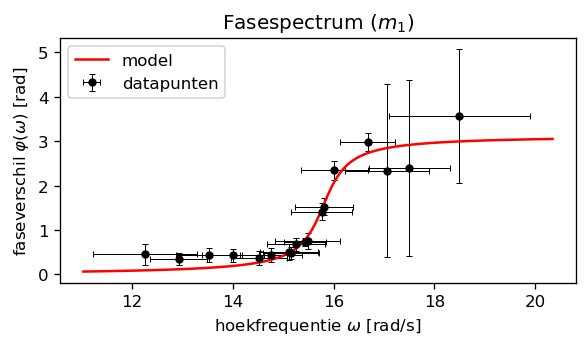

For parameter $\frac{\eta}{m}$ :     Minimum at      -0.73780361     ;     68% CI = [     -0.87484930,      -0.61807836]
For parameter $\omega_0$ :     Minimum at      15.80306738     ;     68% CI = [     15.75519133,      15.85322357]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min          16.66180265
Reduced χ² value       :     χ²_red           1.04136267
P-value                :     p-value          0.40780109


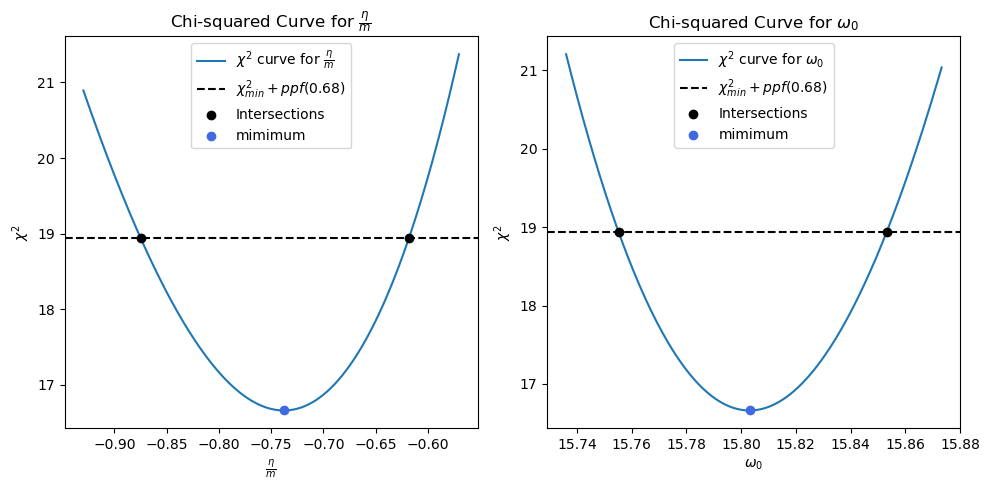

----------END---------------------------------------------------------------------------------------------------

0.13704569 -0.11972525 0.04787604999999928


In [6]:
###FASEVERSCHIL

#tampering: +np.pi voor juiste kwadrant

param_names = [r'$\frac{\eta}{m}$', r'$\omega_0$']
title = r'Fasespectrum ($m_1$)'
x_label = r'hoekfrequentie $\omega$ [rad/s]'
y_label = r'faseverschil $\varphi(\omega)$ [rad]'

X_sq(((freq1[7:], dfreq1[7:]), (phase1[7:], dphase1[7:])), param_names, (0.75, 15.87), model = faseverschil, graf1_title=title, graf1_x_label = x_label, graf1_y_label = y_label)
print(-0.73780361 + 0.87484930, -0.73780361 + 0.61807836, 15.80306738 -15.75519133)


---------START--------------------------------------------------------------------------------------------------


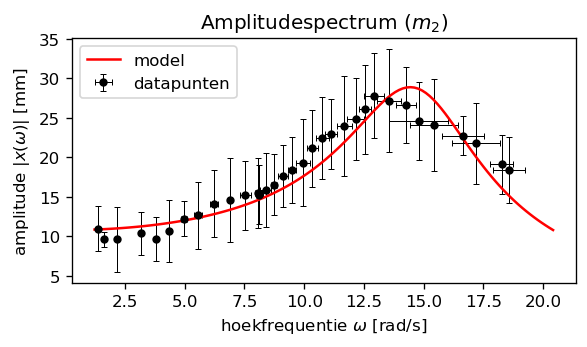

For parameter $\frac{F_0}{m}$ :     Minimum at    2429.72082953     ;     68% CI = [   2260.69111750,    2598.75069059]
For parameter $\frac{\eta}{m}$ :     Minimum at       5.71112208     ;     68% CI = [      5.01721887,       6.54881944]
For parameter $\omega_0$ :     Minimum at      14.99446513     ;     68% CI = [     14.53436059,      15.49253498]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min           7.22419906
Reduced χ² value       :     χ²_red           0.24080664
P-value                :     p-value          0.99999383


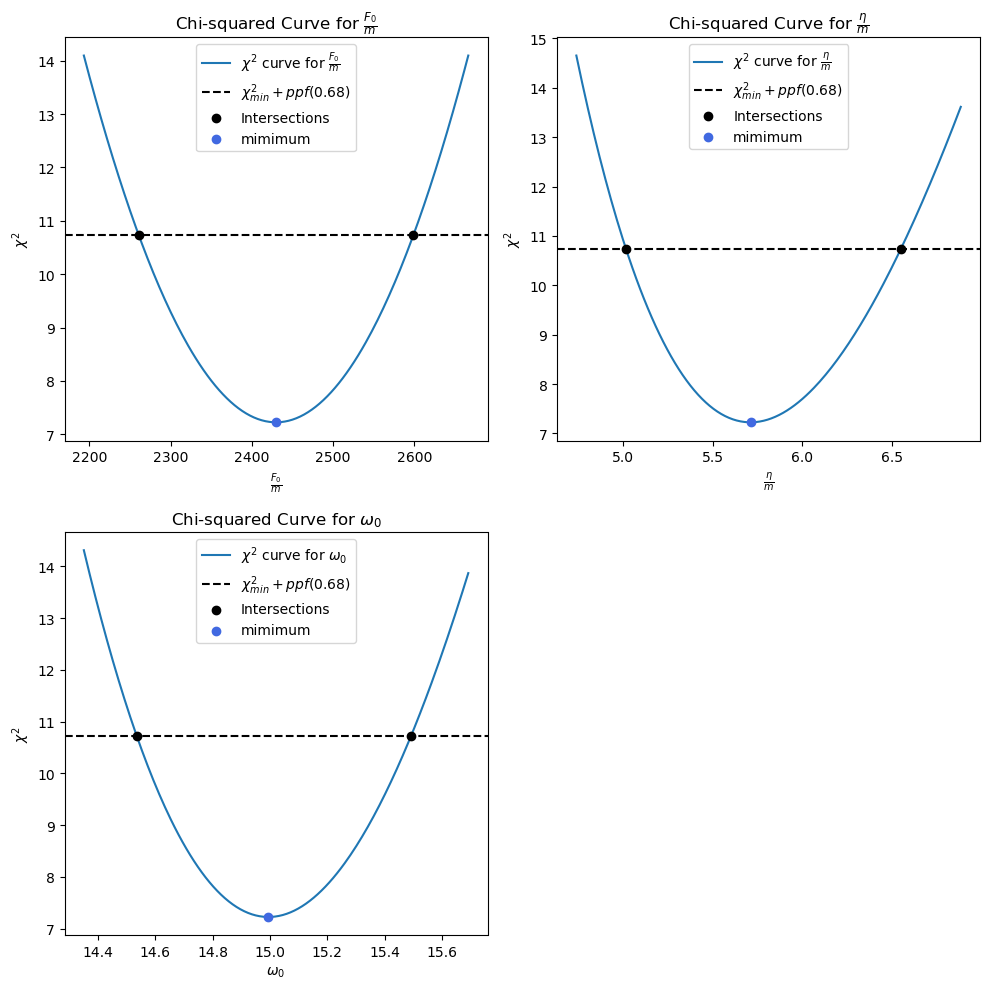

----------END---------------------------------------------------------------------------------------------------

169.02971203000016 169.0298610599998 0.6939032100000002 0.83769736 0.4601045399999997 0.49806985000000026


In [7]:
###########################################
#FITTEN DATASET 2
###########################################

###AMPLITUDE

#tampering: geen nullen in damp2
#eerste meting weggelaten

param_names = [r'$\frac{F_0}{m}$', r'$\frac{\eta}{m}$', r'$\omega_0$']
title = r'Amplitudespectrum ($m_2$)'
x_label = r'hoekfrequentie $\omega$ [rad/s]'
y_label = r'amplitude $|{x(\omega)}|$ [mm]'

X_sq(((freq2[1:], dfreq2[1:]), (amp2[1:], damp2[1:])), param_names = param_names, initial_guess = (2429.72082953, 5.71112208, 14.99446513), graf1_title = title, graf1_x_label = x_label, graf1_y_label = y_label, model = amplitude)
print(2429.72082953-2260.69111750, 2598.75069059 - 2429.72082953, 5.71112208-5.01721887, 6.54881944-5.71112208, 14.99446513 - 14.53436059,  15.49253498 - 14.99446513)


---------START--------------------------------------------------------------------------------------------------


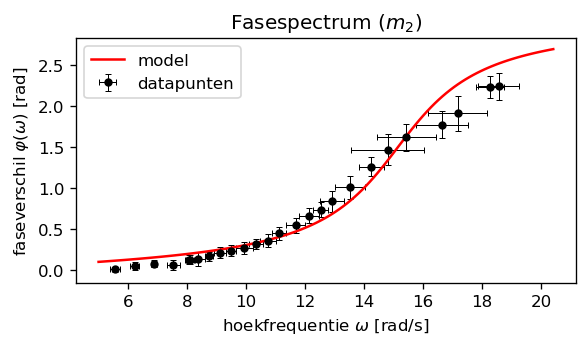

For parameter $\frac{\eta}{m}$ :     Minimum at      -4.25535970     ;     68% CI = [     -4.58533427,      -3.93605509]
For parameter $\omega_0$ :     Minimum at      15.29879930     ;     68% CI = [     15.09065756,      15.51842729]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min          54.62921040
Reduced χ² value       :     χ²_red           2.27621710
P-value                :     p-value          0.00035113


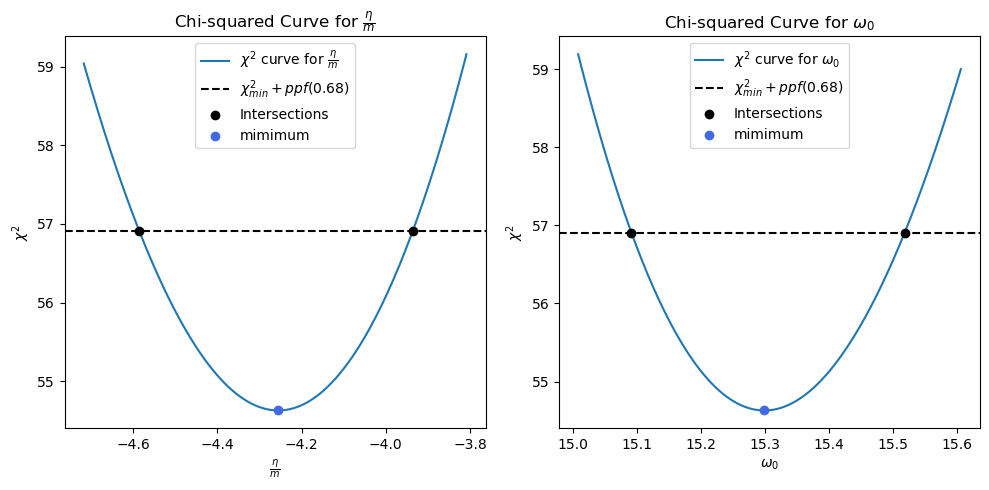

----------END---------------------------------------------------------------------------------------------------

0.3299745700000001 -0.31930460999999966 0.2081417400000003 0.21962798999999933


In [9]:
###FASEVERSCHIL

param_names = [r'$\frac{\eta}{m}$', r'$\omega_0$']
title = r'Fasespectrum ($m_2$)'
x_label = r'hoekfrequentie $\omega$ [rad/s]'
y_label = r'faseverschil $\varphi(\omega)$ [rad]'

#tampering: eesrte waardes weg en ook laatste een beetje (3)

X_sq(((freq2[8:], dfreq2[8:]), (phase2[8:], dphase2[8:])), param_names, (5.7, 14.99), faseverschil, graf1_title = title, graf1_x_label = x_label, graf1_y_label = y_label)
print(-4.25535970 + 4.58533427, -4.25535970 + 3.93605509, 15.29879930 - 15.09065756, 15.51842729 - 15.29879930)